# Storm surge — Bathtub with the ECMWF HRES wind at 25 km and 9 km

Effect of the wind resolution on the bathtub surge, for Hurricane Melissa (Jamaica).

The ECMWF ensemble at 9 km is not available for past storms, so the test uses the deterministic **HRES** forecast, very
close to the ensemble control member, at two resolutions:

| Wind | Source |
|---|---|
| HRES 0.25° (~25 km) | ECMWF open data, AWS archive (stream `oper` at 00/12z, `scda` at 06/18z) |
| HRES 9 km | Open-Meteo Single Runs API (`ecmwf_ifs`) |

**Runs:** 27, 28 and 29 October 2025, at 00, 06, 12 and 18 UTC (12 runs). Landfall in Jamaica: 28 October, 17:25 UTC
(NHC Tropical Cyclone Report).

**Same set-up for both winds:** maximum wind over 0–48 h, every 3 h, interpolated at the same 2913 coastal cells, SRTM
elevation. The coastal cells and the cell elevation are read from the bathtub notebook outputs (`outputs/bathtub/`).

In [46]:
# Environment: PROJ database, warnings and log messages off
import os
import sys
import logging
import warnings
from pathlib import Path

proj_dir = str(Path(sys.prefix) / "share" / "proj")
os.environ["PROJ_DATA"] = proj_dir
os.environ["PROJ_LIB"] = proj_dir
os.environ["PYTHONWARNINGS"] = "ignore"
import pyproj
pyproj.datadir.set_data_dir(proj_dir)

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

In [47]:
import time
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import requests
import matplotlib.pyplot as plt
from scipy import sparse
from ecmwf.opendata import Client

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CONFIG = {
    "storm_name": "MELISSA",
    "run_dates": ["2025-10-27", "2025-10-28", "2025-10-29"],
    "run_hours": [0, 6, 12, 18],
    "steps_h": list(range(0, 49, 3)),             # 0-48 h, every 3 h, for both winds
    "landfall": "2025-10-28T17:25",               # NHC Tropical Cyclone Report
    "points_file": PROJECT / "outputs/bathtub/melissa_20251028_00z_coastal_points.parquet",
    "cell_dem": PROJECT / "outputs/bathtub/melissa_20251028_00z_srtm_cell_mean_15as.tif",
    "wind_dir": PROJECT / "data/wind/hres",
    "output_dir": PROJECT / "outputs/hres_resolution",
    "om_step_deg": 0.1,                           # Open-Meteo sampling grid (~ native 9 km)
    "om_batch": 100,                              # points per Open-Meteo request
    "wind_min_kt": 34,
    "inland_decay_m_per_km": 0.2,
    "sea_level_rise_m": 0.0,
}
OUT = CONFIG["output_dir"]
OUT.mkdir(parents=True, exist_ok=True)
CONFIG["wind_dir"].mkdir(parents=True, exist_ok=True)

RUNS = [pd.Timestamp(f"{d} {h:02d}:00") for d in CONFIG["run_dates"] for h in CONFIG["run_hours"]]
print(f"{len(RUNS)} runs: {RUNS[0]:%d %b %Hz} to {RUNS[-1]:%d %b %Hz}")

12 runs: 27 Oct 00z to 29 Oct 18z


## 1. Coastal cells

Same 2913 cells and SRTM cell elevation as the bathtub notebook.

In [48]:
points = pd.read_parquet(CONFIG["points_file"])
assert CONFIG["cell_dem"].exists(), f"Missing {CONFIG['cell_dem'].name}: run the bathtub notebook first"
west, east = points["lon"].min() - 0.2, points["lon"].max() + 0.2
south, north = points["lat"].min() - 0.2, points["lat"].max() + 0.2
print(f"{len(points)} coastal cells | box lon {west:.1f} to {east:.1f}, lat {south:.1f} to {north:.1f}")

2913 coastal cells | box lon -78.6 to -76.0, lat 17.5 to 18.7


## 2. HRES wind at 25 km (ECMWF open data)

One GRIB file per run, cached in `data/wind/hres/`. The 06z and 18z HRES runs are published as stream `scda`.

In [49]:
WIND_PARAMS = {"u10": 165, "v10": 166}      # GRIB paramId of 10u and 10v


def hres025_file(run):
    return CONFIG["wind_dir"] / f"ecmwf_hres025_10uv_{run:%Y%m%d_%H}z_0-48h.grib2"


def read_param(f, param_id):
    """One wind component from the GRIB, as a DataArray."""
    ds = xr.open_dataset(f, engine="cfgrib",
                         backend_kwargs={"indexpath": "", "filter_by_keys": {"paramId": param_id}})
    return ds[list(ds.data_vars)[0]]


def hres025_complete(f):
    """True when the GRIB has u10 and v10 for all the requested steps."""
    try:
        return all(read_param(f, pid).sizes.get("step", 1) == len(CONFIG["steps_h"])
                   for pid in WIND_PARAMS.values())
    except Exception:
        return False


def download_hres025(run, tries=3):
    f = hres025_file(run)
    for _ in range(tries):
        if f.exists() and hres025_complete(f):
            return f
        f.unlink(missing_ok=True)
        tmp = f.with_suffix(".part")
        Client(source="aws").retrieve(
            date=f"{run:%Y-%m-%d}", time=run.hour, stream="oper" if run.hour in (0, 12) else "scda",
            type="fc", step=CONFIG["steps_h"], param=["10u", "10v"], target=str(tmp))
        tmp.rename(f)
    raise RuntimeError(f"{f.name}: still incomplete after {tries} downloads")


def max_wind_025(run):
    """Maximum 10 m wind speed (m/s) over the steps, on the 0.25° grid around Jamaica."""
    f = hres025_file(run)
    ds = xr.Dataset({name: read_param(f, pid) for name, pid in WIND_PARAMS.items()})
    if float(ds.longitude.max()) > 180:
        ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
    ds = ds.sortby("latitude").sel(latitude=slice(south - 1, north + 1), longitude=slice(west - 1, east + 1))
    return np.sqrt(ds["u10"] ** 2 + ds["v10"] ** 2).max(dim="step").load()


t0 = time.perf_counter()
for run in RUNS:
    download_hres025(run)
    print(f"  {run:%d %b %Hz} complete")
print(f"HRES 25 km: {len(RUNS)} runs ready ({time.perf_counter() - t0:.0f} s)")

  27 Oct 00z complete
  27 Oct 06z complete
  27 Oct 12z complete
  27 Oct 18z complete
  28 Oct 00z complete
  28 Oct 06z complete


<multiple>:   0%|          | 0.00/26.4M [00:00<?, ?B/s]

  28 Oct 12z complete
  28 Oct 18z complete


<multiple>:   0%|          | 0.00/27.2M [00:00<?, ?B/s]

  29 Oct 00z complete
  29 Oct 06z complete
  29 Oct 12z complete
  29 Oct 18z complete
HRES 25 km: 12 runs ready (17 s)


## 3. HRES wind at 9 km (Open-Meteo)

Hourly 10 m wind on a 0.1° grid over Jamaica, cached as one NetCDF per run in `data/wind/hres/`. Only the hours of
`steps_h` (every 3 h) are kept, as for the 25 km wind. When the free API limit is reached, the loop waits 60 s.

In [50]:
lats = np.round(np.arange(south, north + 0.05, CONFIG["om_step_deg"]), 2)
lons = np.round(np.arange(west, east + 0.05, CONFIG["om_step_deg"]), 2)
glat, glon = [a.ravel() for a in np.meshgrid(lats, lons, indexing="ij")]


def hres9_file(run):
    return CONFIG["wind_dir"] / f"openmeteo_hres9km_ws10_{run:%Y%m%d_%H}z_0-48h.nc"


def download_hres9(run):
    f = hres9_file(run)
    if f.exists():
        return f
    ws = np.full((len(glat), 49), np.nan, dtype="float32")
    for i in range(0, len(glat), CONFIG["om_batch"]):
        for _ in range(10):
            r = requests.get("https://single-runs-api.open-meteo.com/v1/forecast", params={
                "latitude": ",".join(map(str, glat[i:i + CONFIG["om_batch"]])),
                "longitude": ",".join(map(str, glon[i:i + CONFIG["om_batch"]])),
                "run": f"{run:%Y-%m-%dT%H:%M}", "models": "ecmwf_ifs",
                "hourly": "wind_speed_10m", "wind_speed_unit": "ms",
            }, timeout=120)
            if r.status_code != 429:
                break
            print("  rate limit reached, waiting 60 s...")
            time.sleep(60)
        r.raise_for_status()
        res = r.json()
        res = res if isinstance(res, list) else [res]
        for k, d in enumerate(res):
            v = np.array(d["hourly"]["wind_speed_10m"][:49], dtype="float32")
            ws[i + k, :len(v)] = v
        time.sleep(1)
    da = xr.DataArray(ws.reshape(len(lats), len(lons), 49), dims=("latitude", "longitude", "step"),
                      coords={"latitude": lats, "longitude": lons, "step": np.arange(49)}, name="ws10")
    da.attrs.update(units="m/s", source="ECMWF IFS HRES 9 km via Open-Meteo Single Runs API",
                    run=f"{run:%Y-%m-%dT%H:%M}")
    da.to_netcdf(f)
    return f


def max_wind_9(run):
    """Maximum 10 m wind speed (m/s) over the same steps as the 25 km wind."""
    da = xr.open_dataarray(hres9_file(run)).sel(step=CONFIG["steps_h"])
    return da.max(dim="step").load()


t0 = time.perf_counter()
for run in RUNS:
    download_hres9(run)
    print(f"  {run:%d %b %Hz} ready")
print(f"HRES 9 km: {len(RUNS)} runs ready, {len(glat)} points each ({time.perf_counter() - t0:.0f} s)")

  27 Oct 00z ready
  27 Oct 06z ready
  27 Oct 12z ready
  27 Oct 18z ready
  28 Oct 00z ready
  28 Oct 06z ready
  28 Oct 12z ready
  28 Oct 18z ready
  29 Oct 00z ready
  29 Oct 06z ready
  29 Oct 12z ready
  29 Oct 18z ready
HRES 9 km: 12 runs ready, 351 points each (0 s)


## 4. Wind at the coastal cells

Maximum wind over 0–48 h, interpolated (bilinear) at each cell centre. Wind below 34 kt is set to 0.
One row per run and resolution.

In [51]:
plat = xr.DataArray(points["lat"].values, dims="point")
plon = xr.DataArray(points["lon"].values, dims="point")

events, winds = [], []
for run in RUNS:
    for res_name, wmax in [("25 km", max_wind_025(run)), ("9 km", max_wind_9(run))]:
        w = np.nan_to_num(wmax.interp(latitude=plat, longitude=plon, method="linear").values)
        w[w < CONFIG["wind_min_kt"] * 0.514444] = 0.0
        events.append({"run": run, "resolution": res_name})
        winds.append(w)
wind_ms = np.vstack(winds).astype("float32")               # (run x resolution, cells)
events = pd.DataFrame(events)
print(f"Wind matrix: {wind_ms.shape[0]} forecasts x {wind_ms.shape[1]} cells")

Wind matrix: 24 forecasts x 2913 cells


## 5. Surge — CLIMADA `TCSurgeBathtub`

All forecasts in one CLIMADA `Hazard` (one event per run and resolution), same settings as the bathtub notebook.

In [52]:
from climada.hazard import Centroids, Hazard
from climada_petals.hazard import TCSurgeBathtub

n_ev, n_pts = wind_ms.shape
centroids = Centroids(lat=points["lat"].values, lon=points["lon"].values)
_signed_dist_m = -points["dist_coast_km"].values * 1000
centroids.get_dist_coast = lambda signed=False, precomputed=True: _signed_dist_m if signed else np.abs(_signed_dist_m)

wind_haz = Hazard(
    haz_type="TC", units="m/s", centroids=centroids,
    event_id=np.arange(1, n_ev + 1),
    event_name=[f"{r:%Y%m%d_%H}z_{s.replace(' ', '')}" for r, s in zip(events["run"], events["resolution"])],
    frequency=np.ones(n_ev), date=np.array([r.toordinal() for r in events["run"]]),
    orig=np.zeros(n_ev, dtype=bool),
    intensity=sparse.csr_matrix(wind_ms), fraction=sparse.csr_matrix((n_ev, n_pts)),
)
surge_haz = TCSurgeBathtub.from_tc_winds(
    wind_haz, str(CONFIG["cell_dem"]),
    inland_decay_rate=CONFIG["inland_decay_m_per_km"], add_sea_level_rise=CONFIG["sea_level_rise_m"])
depth = surge_haz.intensity.toarray().astype("float32")  # (forecasts, cells), metres
print(f"{n_ev} forecasts | max depth {depth.max():.2f} m")

24 forecasts | max depth 2.13 m


## 6. Comparison

One row per run, 25 km and 9 km side by side. Cell area: 15″ cells (~0.2 km²).

In [53]:
cell_km2 = (15 / 3600 * 111.32) ** 2 * np.cos(np.radians(points["lat"].values))
landfall = pd.Timestamp(CONFIG["landfall"])

res = events.copy()
res["hours_before_landfall"] = ((landfall - res["run"]).dt.total_seconds() / 3600).round(1)
res["max_wind_kt"] = (wind_ms.max(axis=1) / 0.514444).round(0)
res["max_depth_m"] = depth.max(axis=1).round(2)
res["cells_ge_0.5m"] = (depth >= 0.5).sum(axis=1)
res["cells_ge_1m"] = (depth >= 1.0).sum(axis=1)
res["km2_ge_0.5m"] = [round(float(cell_km2[d >= 0.5].sum()), 1) for d in depth]
res.to_csv(OUT / "melissa_hres_25km_vs_9km.csv", index=False)

table = res.pivot(index=["run", "hours_before_landfall"], columns="resolution",
                  values=["max_wind_kt", "max_depth_m", "cells_ge_0.5m", "cells_ge_1m"])
table = table.reindex(columns=["25 km", "9 km"], level=1)
table.index = [f"{r:%d %b %Hz} ({h:+.0f} h)" for r, h in table.index]
table

max_wind_kt       max_depth_m       cells_ge_0.5m        \
resolution               25 km  9 km       25 km  9 km         25 km  9 km   
27 Oct 00z (+41 h)        61.0  56.0        1.19  1.19          30.0  29.0   
27 Oct 06z (+35 h)        65.0  65.0        1.19  1.24          29.0  13.0   
27 Oct 12z (+29 h)        66.0  68.0        1.55  1.09          41.0  16.0   
27 Oct 18z (+23 h)        66.0  63.0        1.37  1.19          31.0  25.0   
28 Oct 00z (+17 h)        61.0  77.0        1.46  1.40          37.0  22.0   
28 Oct 06z (+11 h)        77.0  72.0        2.13  1.19          52.0  29.0   
28 Oct 12z (+5 h)         60.0  62.0        1.26  1.26          31.0  30.0   
28 Oct 18z (-1 h)         50.0  46.0        1.26  1.26          31.0  31.0   
29 Oct 00z (-7 h)         41.0  39.0        0.55  0.00           1.0   0.0   
29 Oct 06z (-13 h)         0.0   0.0        0.00  0.00           0.0   0.0   
29 Oct 12z (-19 h)         0.0   0.0        0.00  0.00           0.0   0.0   
29 Oct 18z (-25 h)         0.0   0.0        0.00  0.00           0.0   0.0   

                   cells_ge_1m       
resolution               25 km 9 km  
27 Oct 00z (+41 h)         6.0  6.0  
27 Oct 06z (+35 h)         6.0  2.0  
27 Oct 12z (+29 h)        11.0  2.0  
27 Oct 18z (+23 h)         6.0  5.0  
28 Oct 00z (+17 h)         8.0  5.0  
28 Oct 06z (+11 h)        16.0  6.0  
28 Oct 12z (+5 h)          7.0  7.0  
28 Oct 18z (-1 h)          7.0  7.0  
29 Oct 00z (-7 h)          0.0  0.0  
29 Oct 06z (-13 h)         0.0  0.0  
29 Oct 12z (-19 h)         0.0  0.0  
29 Oct 18z (-25 h)         0.0  0.0

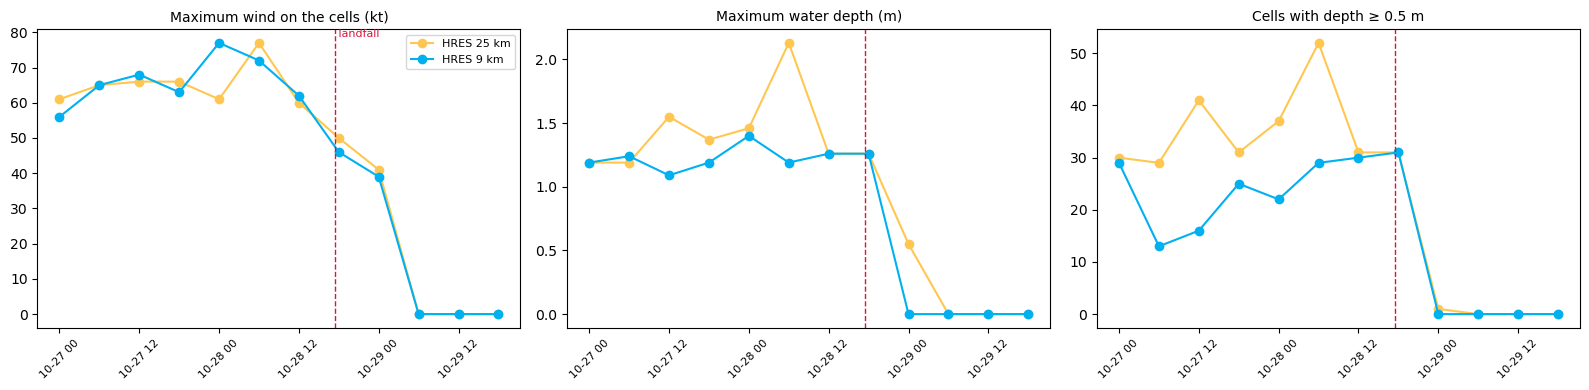

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, label in zip(axes, ["max_wind_kt", "max_depth_m", "cells_ge_0.5m"],
                          ["Maximum wind on the cells (kt)", "Maximum water depth (m)", "Cells with depth ≥ 0.5 m"]):
    for res_name, color in [("25 km", "#FFC751"), ("9 km", "#00B0F0")]:
        s = res[res["resolution"] == res_name]
        ax.plot(s["run"], s[col], marker="o", color=color, label=f"HRES {res_name}")
    ax.axvline(landfall, color="crimson", linestyle="--", linewidth=1)
    ax.set_title(label, fontsize=10)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
axes[0].text(landfall, axes[0].get_ylim()[1], " landfall", color="crimson", fontsize=8, va="top")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "melissa_hres_25km_vs_9km.png", dpi=150)
plt.show()